# <center>Taller de Aprendizaje Automático</center>
## <center>Taller 5: Experimentación extendida del Higgs con redes neuronales</center>

## Sub objetivos

Parte 2: entrenar un `baseline` MLP reproducible sobre el dataset procesado del challenge Higgs.

Parte 3: extender la búsqueda manual del baseline para comparar variantes arquitectónicas razonables.

Parte 4: adaptar la estrategia del taller de demanda de bicicletas a este problema de clasificación usando `Keras Tuner`.

Parte 5: repetir la exploración con `Optuna` para ampliar la búsqueda de hiperparámetros.

Parte 6: consolidar una comparativa final entre todos los enfoques para decidir qué variante conviene seguir explorando.

## Introducción

Este notebook toma como punto de partida el `baseline` MLP ya armado para Higgs y lo extiende con una lógica de experimentación inspirada en el notebook del taller de demanda de bicicletas con redes neuronales.

La adaptación no es literal: en bicicletas el problema es de regresión y acá es de **clasificación binaria**. Por eso, en lugar de optimizar `val_loss` de regresión, se prioriza `val_auc` como criterio principal de comparación, manteniendo además `accuracy`, `precision` y `recall` para interpretar mejor los cambios.

Se parte directamente de los artefactos generados en `data/higgs-boson/processed/i1/`, de modo que este cuaderno queda enfocado en modelado y ajuste fino, no en preprocesamiento.

## Preparación de datos

Se cargan `X_train_processed.csv`, `y_train.csv`, `X_test_processed.csv` y `test_event_id.csv`. El dataset etiquetado se usa para armar `train/validación`, mientras que `X_test_processed` se mantiene separado como conjunto externo sin etiquetas para inferencia posterior.

In [1]:
from pathlib import Path
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
import tensorflow as tf

try:
    import keras_tuner as kt
except ImportError as exc:
    raise ImportError(
        "No se pudo importar keras_tuner. Instalar con `%pip install keras-tuner`."
    ) from exc

try:
    import optuna
except ImportError as exc:
    raise ImportError(
        "No se pudo importar optuna. Instalar con `%pip install optuna`."
    ) from exc

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


def find_processed_data_dir() -> Path:
    """Busca el directorio de datos procesados desde el cwd actual."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "data" / "higgs-boson" / "processed" / "i1"
        if candidate.exists():
            return candidate
    raise FileNotFoundError("No se encontro data/higgs-boson/processed/i1")


data_dir = find_processed_data_dir()
print(f"Data dir: {data_dir}")

I0000 00:00:1776604337.702020   17784 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1776604337.758989   17784 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/lib/python3/dist-packages/requests/__init__.py:87: RequestsDependencyWarning: urllib3 (2.6.3) or chardet (4.0.0) doesn't match a supported version!
  warnings.warn("urllib3 ({}) or chardet ({}) doesn't match a supported "
I0000 00:00:1776604339.141621   17784 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Data dir: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i1


/home/santig14/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_labeled_full = pd.read_csv(data_dir / "X_train_processed.csv")
y_labeled_full = pd.read_csv(data_dir / "y_train.csv")
X_test_processed = pd.read_csv(data_dir / "X_test_processed.csv")
test_event_id = pd.read_csv(data_dir / "test_event_id.csv")

if list(X_labeled_full.columns) != list(X_test_processed.columns):
    raise ValueError("Las columnas de train y X_test_processed no coinciden.")

if len(X_test_processed) != len(test_event_id):
    raise ValueError("La cantidad de filas de X_test_processed y test_event_id no coincide.")

X = X_labeled_full.astype(np.float32)
y = y_labeled_full["Label"].map({"b": 0, "s": 1}).astype(np.int8)
X_test = X_test_processed.astype(np.float32)

print(f"X labeled shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"X_test_processed shape: {X_test.shape}")
print(f"test_event_id shape: {test_event_id.shape}")
print("Class distribution:")
display(y.value_counts().rename(index={0: "b", 1: "s"}))

X labeled shape: (250000, 26)
y shape: (250000,)
X_test_processed shape: (550000, 26)
test_event_id shape: (550000, 1)
Class distribution:


Label
b    164333
s     85667
Name: count, dtype: int64

## Train / validation split

Se reserva un 10% del dataset etiquetado para validación usando un split estratificado. `X_test_processed` no participa de este paso porque se conserva como conjunto externo sin etiquetas.

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=SEED,
    stratify=y,
)

X_train_np = X_train.to_numpy(dtype=np.float32)
X_valid_np = X_valid.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)
y_train_np = y_train.to_numpy(dtype=np.float32)
y_valid_np = y_valid.to_numpy(dtype=np.float32)

classes = np.array([0, 1])
class_weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train_np.astype(int))
class_weight = {int(cls): float(weight) for cls, weight in zip(classes, class_weights)}

print(f"Train shape: {X_train_np.shape}")
print(f"Valid shape: {X_valid_np.shape}")
print(f"External test shape: {X_test_np.shape}")
print(f"Class weight: {class_weight}")

Train shape: (225000, 26)
Valid shape: (25000, 26)
External test shape: (550000, 26)
Class weight: {0: 0.7606490872210954, 1: 1.4591439688715953}


## Parte 2 - Baseline MLP

La red de referencia conserva el espíritu del baseline original: una sola capa oculta densa y una salida `sigmoid` para clasificación binaria. A partir de acá, el resto de las secciones intentan mejorar ese punto de partida cambiando arquitectura y algunos hiperparámetros de entrenamiento.

In [4]:
INPUT_DIM = X_train_np.shape[1]
BASELINE_UNITS = 32
BASELINE_LR = 1e-3
BASELINE_BATCH_SIZE = 1024
BASELINE_EPOCHS = 20


def plot_history(history: keras.callbacks.History, title: str) -> None:
    history_df = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history_df.index + 1, history_df["loss"], label="train")
    axes[0].plot(history_df.index + 1, history_df["val_loss"], label="valid")
    axes[0].set_title(f"{title} - loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Binary crossentropy")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history_df.index + 1, history_df["auc"], label="train")
    axes[1].plot(history_df.index + 1, history_df["val_auc"], label="valid")
    axes[1].set_title(f"{title} - AUC")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("AUC")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


def make_callbacks() -> list[keras.callbacks.Callback]:
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_auc",
            mode="max",
            patience=4,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
        ),
    ]


def final_metrics(model: keras.Model, name: str) -> dict:
    metrics = model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
    return {"model": name, **metrics}


def build_baseline_model(input_dim: int = INPUT_DIM, learning_rate: float = BASELINE_LR) -> keras.Model:
    model = keras.Sequential([
        keras.layers.Input(shape=(input_dim,)),
        keras.layers.Dense(BASELINE_UNITS, activation="relu", kernel_initializer="he_normal"),
        keras.layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
baseline_model = build_baseline_model()
baseline_model.summary()

manual_params = (INPUT_DIM + 1) * BASELINE_UNITS + (BASELINE_UNITS + 1) * 1
print(f"Parametros entrenables (manual): {manual_params}")
print(f"Parametros entrenables (Keras): {baseline_model.count_params()}")

E0000 00:00:1776604343.752981   17784 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1776604343.753281   17863 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1776604343.775862   17784 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

Parametros entrenables (manual): 897
Parametros entrenables (Keras): 897


W0000 00:00:1776604343.953043   17784 cpu_allocator_impl.cc:82] Allocation of 23400000 exceeds 10% of free system memory.


Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6835 - auc: 0.7660 - loss: 0.5786 - precision: 0.5268 - recall: 0.7516 - val_accuracy: 0.7519 - val_auc: 0.8314 - val_loss: 0.5058 - val_precision: 0.6086 - val_recall: 0.7731 - learning_rate: 0.0010
Epoch 2/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7692 - auc: 0.8547 - loss: 0.4776 - precision: 0.6292 - recall: 0.7951 - val_accuracy: 0.7835 - val_auc: 0.8670 - val_loss: 0.4586 - val_precision: 0.6489 - val_recall: 0.8021 - learning_rate: 0.0010
Epoch 3/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7891 - auc: 0.8763 - loss: 0.4457 - precision: 0.6549 - recall: 0.8127 - val_accuracy: 0.7937 - val_auc: 0.8787 - val_loss: 0.4413 - val_precision: 0.6621 - val_recall: 0.8130 - learning_rate: 0.0010
Epoch 4/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7976 - auc: 0.8841 - loss: 0.4329 - precision: 0.6664 - recall: 0.8194 - val_accuracy: 0.8000 - val_auc: 0.8833 - val_loss: 0.4337 - val

,input_dim,hidden_layers,hidden_units,learning_rate,batch_size,epochs_ran,trainable_params_manual,trainable_params_keras,accuracy,auc,loss,precision,recall
0,26,1,32,0.001,1024,20,897,897,0.8133,0.8965,0.4078,0.6899,0.8269


Historial de entrenamiento por epoca:


,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate
0,0.6835,0.7660,0.5786,0.5268,0.7516,0.7519,0.8314,0.5058,0.6086,0.7731,0.001
1,0.7692,0.8547,0.4776,0.6292,0.7951,0.7835,0.8670,0.4586,0.6489,0.8021,0.001
2,0.7891,0.8763,0.4457,0.6549,0.8127,0.7937,0.8787,0.4413,0.6621,0.8130,0.001
3,0.7976,0.8841,0.4329,0.6664,0.8194,0.8000,0.8833,0.4337,0.6702,0.8195,0.001
4,0.8017,0.8879,0.4262,0.6720,0.8227,0.8020,0.8861,0.4289,0.6738,0.8183,0.001
5,0.8046,0.8903,0.4217,0.6761,0.8250,0.8044,0.8880,0.4254,0.6770,0.8212,0.001
6,0.8067,0.8920,0.4183,0.6792,0.8263,0.8064,0.8894,0.4228,0.6795,0.8230,0.001
7,0.8080,0.8933,0.4158,0.6808,0.8276,0.8062,0.8904,0.4208,0.6792,0.8235,0.001
8,0.8089,0.8943,0.4139,0.6823,0.8279,0.8063,0.8912,0.4191,0.6793,0.8236,0.001
9,0.8099,0.8952,0.4122,0.6836,0.8286,0.8078,0.8920,0.4176,0.6813,0.8253,0.001


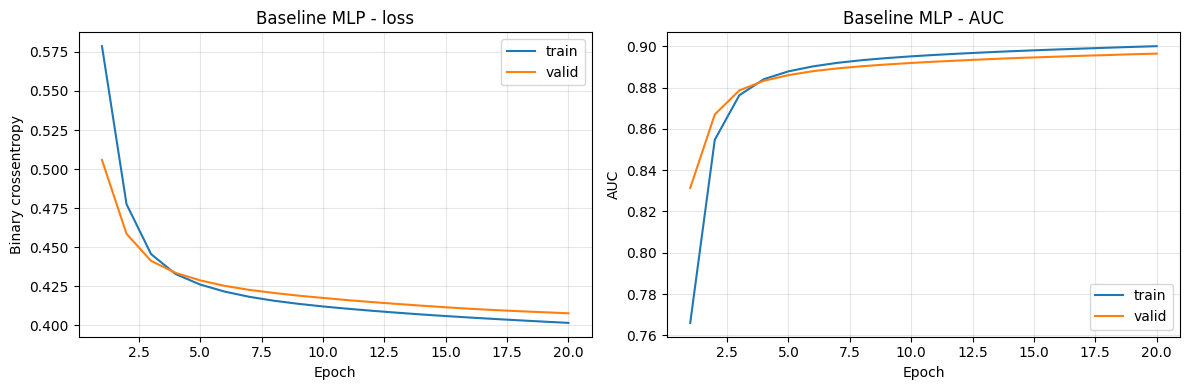

In [5]:
baseline_history = baseline_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=BASELINE_EPOCHS,
    batch_size=BASELINE_BATCH_SIZE,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=1,
)

baseline_eval = baseline_model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
baseline_history_df = pd.DataFrame(baseline_history.history)

baseline_summary_df = pd.DataFrame(
    [
        {
            "input_dim": INPUT_DIM,
            "hidden_layers": 1,
            "hidden_units": BASELINE_UNITS,
            "learning_rate": BASELINE_LR,
            "batch_size": BASELINE_BATCH_SIZE,
            "epochs_ran": len(baseline_history_df),
            "trainable_params_manual": manual_params,
            "trainable_params_keras": baseline_model.count_params(),
            **{metric: float(value) for metric, value in baseline_eval.items()},
        }
    ]
)

print("Resumen del baseline MLP:")
display(baseline_summary_df.round(4))

print("Historial de entrenamiento por epoca:")
display(baseline_history_df.round(4))

plot_history(baseline_history, "Baseline MLP")

## Parte 3 - Búsqueda manual extendida

Antes de pasar a métodos automáticos, se conserva una búsqueda manual corta para tener una referencia interpretable. Esta parte sigue la línea del notebook base y compara unas pocas configuraciones razonables cambiando:

- cantidad de capas ocultas,
- cantidad de neuronas por capa,
- learning rate,
- y si conviene o no que la primera capa sea más ancha.

In [6]:
MANUAL_SEARCH_EPOCHS = 12
MANUAL_SEARCH_BATCH_SIZE = 1024


def build_configurable_model(
    input_dim: int,
    n_hidden: int,
    n_units: int,
    learning_rate: float,
    first_layer_wider: bool,
) -> keras.Model:
    inputs = keras.layers.Input(shape=(input_dim,))
    x = inputs

    for layer_idx in range(n_hidden):
        units = n_units * 2 if first_layer_wider and layer_idx == 0 else n_units
        x = keras.layers.Dense(units, kernel_initializer="he_normal", use_bias=False)(x)
        x = keras.layers.BatchNormalization()(x)
        x = keras.layers.Activation("relu")(x)

    outputs = keras.layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


search_configs = [
    {
        "name": "cfg_1",
        "n_hidden": 1,
        "n_units": 64,
        "learning_rate": 1e-3,
        "first_layer_wider": False,
    },
    {
        "name": "cfg_2",
        "n_hidden": 2,
        "n_units": 64,
        "learning_rate": 1e-3,
        "first_layer_wider": True,
    },
    {
        "name": "cfg_3",
        "n_hidden": 2,
        "n_units": 128,
        "learning_rate": 5e-4,
        "first_layer_wider": False,
    },
    {
        "name": "cfg_4",
        "n_hidden": 3,
        "n_units": 96,
        "learning_rate": 5e-4,
        "first_layer_wider": True,
    },
    {
        "name": "cfg_5",
        "n_hidden": 3,
        "n_units": 128,
        "learning_rate": 3e-4,
        "first_layer_wider": False,
    },
]

pd.DataFrame(search_configs)

,name,n_hidden,n_units,learning_rate,first_layer_wider
0,cfg_1,1,64,0.0010,False
1,cfg_2,2,64,0.0010,True
2,cfg_3,2,128,0.0005,False
3,cfg_4,3,96,0.0005,True
4,cfg_5,3,128,0.0003,False


W0000 00:00:1776604355.195040   17784 cpu_allocator_impl.cc:82] Allocation of 23400000 exceeds 10% of free system memory.


Resultados de la búsqueda manual:


,name,n_hidden,n_units,learning_rate,first_layer_wider,accuracy,auc,loss,precision,recall,epochs_ran
0,cfg_2,2,64,0.0010,True,0.8149,0.9019,0.4028,0.6890,0.8380,12
1,cfg_3,2,128,0.0005,False,0.8154,0.9017,0.4018,0.6907,0.8355,12
2,cfg_4,3,96,0.0005,True,0.8190,0.9016,0.3982,0.6998,0.8263,12
3,cfg_5,3,128,0.0003,False,0.8170,0.9010,0.4018,0.6945,0.8320,12
4,cfg_1,1,64,0.0010,False,0.8083,0.8944,0.4141,0.6802,0.8317,12


Mejor configuración encontrada:
{'name': 'cfg_2', 'n_hidden': 2, 'n_units': 64, 'learning_rate': 0.001, 'first_layer_wider': True, 'accuracy': 0.8148800134658813, 'auc': 0.9019180536270142, 'loss': 0.4028094410896301, 'precision': 0.6890296339988708, 'recall': 0.8379829525947571, 'epochs_ran': 12}
Comparación del mejor set manual de hiperparámetros:


,model,accuracy,auc,loss,precision,recall,first_layer_wider,epochs_ran
0,same_hp_flipped_first_layer,0.8200,0.9026,0.3950,0.7025,0.8235,False,12
1,best_manual_search,0.8149,0.9019,0.4028,0.6890,0.8380,True,12


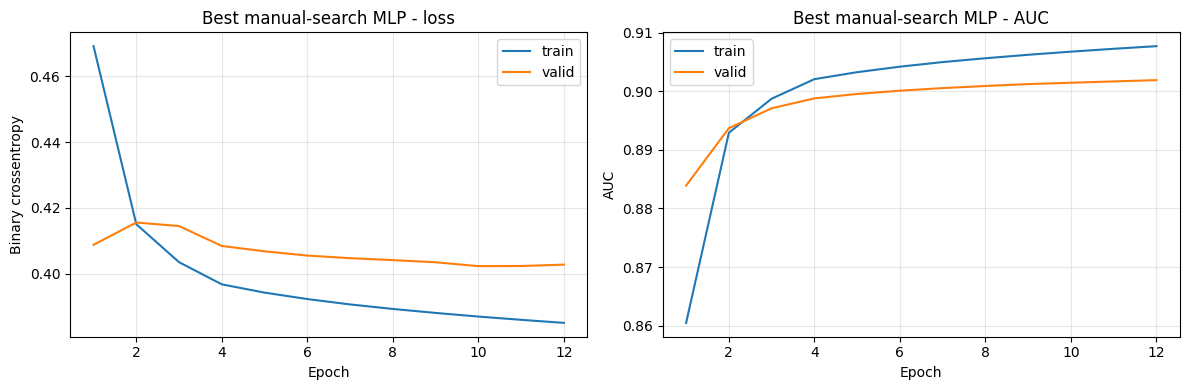

In [7]:
search_results = []
search_histories = {}

for config in search_configs:
    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_configurable_model(
        input_dim=INPUT_DIM,
        n_hidden=config["n_hidden"],
        n_units=config["n_units"],
        learning_rate=config["learning_rate"],
        first_layer_wider=config["first_layer_wider"],
    )
    history = model.fit(
        X_train_np,
        y_train_np,
        validation_data=(X_valid_np, y_valid_np),
        epochs=MANUAL_SEARCH_EPOCHS,
        batch_size=MANUAL_SEARCH_BATCH_SIZE,
        class_weight=class_weight,
        callbacks=make_callbacks(),
        verbose=0,
    )
    metrics = model.evaluate(X_valid_np, y_valid_np, verbose=0, return_dict=True)
    search_results.append({**config, **metrics, "epochs_ran": len(history.history["val_auc"])})
    search_histories[config["name"]] = history

search_results_df = pd.DataFrame(search_results).sort_values(["auc", "recall"], ascending=False).reset_index(drop=True)
best_manual_config = search_results_df.iloc[0].to_dict()

print("Resultados de la búsqueda manual:")
display(search_results_df.round(4))
print("Mejor configuración encontrada:")
print(best_manual_config)


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
best_manual_model = build_configurable_model(
    input_dim=INPUT_DIM,
    n_hidden=int(best_manual_config["n_hidden"]),
    n_units=int(best_manual_config["n_units"]),
    learning_rate=float(best_manual_config["learning_rate"]),
    first_layer_wider=bool(best_manual_config["first_layer_wider"]),
)

best_manual_history = best_manual_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=MANUAL_SEARCH_EPOCHS,
    batch_size=MANUAL_SEARCH_BATCH_SIZE,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
flipped_first_layer_model = build_configurable_model(
    input_dim=INPUT_DIM,
    n_hidden=int(best_manual_config["n_hidden"]),
    n_units=int(best_manual_config["n_units"]),
    learning_rate=float(best_manual_config["learning_rate"]),
    first_layer_wider=not bool(best_manual_config["first_layer_wider"]),
)

flipped_first_layer_history = flipped_first_layer_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=MANUAL_SEARCH_EPOCHS,
    batch_size=MANUAL_SEARCH_BATCH_SIZE,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

best_manual_eval = final_metrics(best_manual_model, "best_manual_search")
flipped_eval = final_metrics(flipped_first_layer_model, "same_hp_flipped_first_layer")

manual_architecture_comparison = pd.DataFrame([
    {
        **best_manual_eval,
        "first_layer_wider": bool(best_manual_config["first_layer_wider"]),
        "epochs_ran": len(best_manual_history.history["val_auc"]),
    },
    {
        **flipped_eval,
        "first_layer_wider": not bool(best_manual_config["first_layer_wider"]),
        "epochs_ran": len(flipped_first_layer_history.history["val_auc"]),
    },
]).sort_values(["auc", "recall"], ascending=False).reset_index(drop=True)

print("Comparación del mejor set manual de hiperparámetros:")
display(manual_architecture_comparison.round(4))

plot_history(best_manual_history, "Best manual-search MLP")

## Parte 4 - Ajuste fino con Keras Tuner

Siguiendo la lógica del taller de bicicletas, acá se reemplaza la búsqueda manual por una exploración automática con `RandomSearch`. La adaptación importante es que el criterio principal pasa a ser `val_auc` en lugar de `val_loss` de regresión.

Search space summary
Default search space size: 4
n_hidden (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 4, 'step': 1, 'sampling': 'linear'}
n_units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 160, 'step': 32, 'sampling': 'linear'}
learning_rate (Float)
{'default': 0.0001, 'conditions': [], 'min_value': 0.0001, 'max_value': 0.002, 'step': None, 'sampling': 'log'}
first_layer_wider (Boolean)
{'default': False, 'conditions': []}
Mejores hiperparámetros encontrados por Keras Tuner:
- n_hidden: 2
- n_units: 64
- learning_rate: 0.0018744290965461122
- first_layer_wider: True
Results summary
Results in models/keras_tuner/higgs_random_search
Showing 10 best trials
Objective(name="val_auc", direction="max")

Trial 2 summary
Hyperparameters:
n_hidden: 2
n_units: 64
learning_rate: 0.0018744290965461122
first_layer_wider: True
Score: 0.90328049659729

Trial 3 summary
Hyperparameters:
n_hidden: 4
n_units: 32
learning_rate: 0.0018058839451529707


,model,accuracy,auc,loss,precision,recall,n_hidden,n_units,learning_rate,first_layer_wider,batch_size,epochs_ran,params
0,best_keras_tuner,0.8142,0.9036,0.4027,0.6862,0.8434,2,64,0.0019,True,1024,16,12353


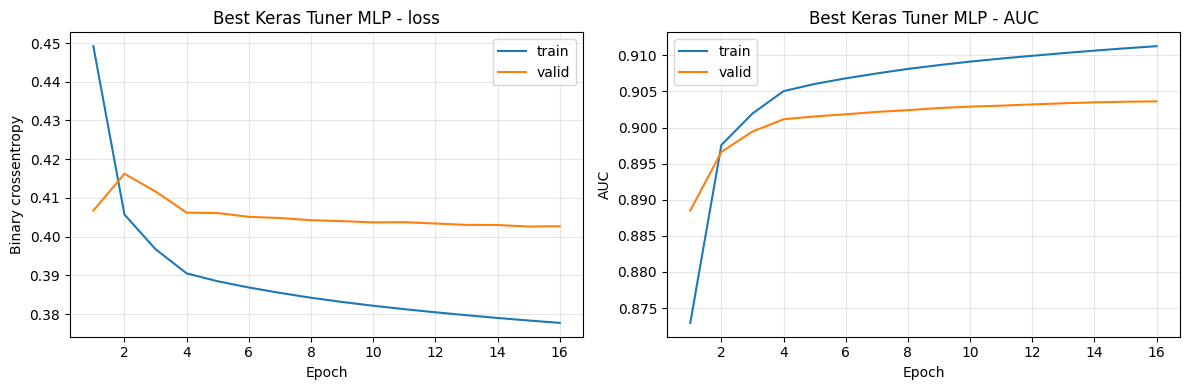

In [8]:
TUNER_EPOCHS = 16
TUNER_BATCH_SIZE = 1024
TUNER_MAX_TRIALS = 8


class RandomSearchNoTensorBoard(kt.RandomSearch):
    """Evita depender de TensorBoard para esta búsqueda acotada."""

    def _configure_tensorboard_dir(self, callbacks, trial, execution=0):
        return


def build_tunable_model(hp: kt.HyperParameters) -> keras.Model:
    n_hidden = hp.Int("n_hidden", min_value=1, max_value=4)
    n_units = hp.Int("n_units", min_value=32, max_value=160, step=32)
    learning_rate = hp.Float("learning_rate", min_value=1e-4, max_value=2e-3, sampling="log")
    first_layer_wider = hp.Boolean("first_layer_wider")

    return build_configurable_model(
        input_dim=INPUT_DIM,
        n_hidden=n_hidden,
        n_units=n_units,
        learning_rate=learning_rate,
        first_layer_wider=first_layer_wider,
    )


tuner_dir = Path("models") / "keras_tuner"
random_search = RandomSearchNoTensorBoard(
    hypermodel=build_tunable_model,
    objective=kt.Objective("val_auc", direction="max"),
    max_trials=TUNER_MAX_TRIALS,
    overwrite=True,
    directory=str(tuner_dir),
    project_name="higgs_random_search",
    seed=SEED,
)

random_search.search_space_summary()

keras.utils.set_random_seed(SEED)
random_search.search(
    X_train_np,
    y_train_np,
    epochs=TUNER_EPOCHS,
    batch_size=TUNER_BATCH_SIZE,
    validation_data=(X_valid_np, y_valid_np),
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

best_hp = random_search.get_best_hyperparameters(num_trials=1)[0]

print("Mejores hiperparámetros encontrados por Keras Tuner:")
for name, value in best_hp.values.items():
    print(f"- {name}: {value}")

random_search.results_summary()


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
best_tuner_model = random_search.hypermodel.build(best_hp)
best_tuner_history = best_tuner_model.fit(
    X_train_np,
    y_train_np,
    epochs=TUNER_EPOCHS,
    batch_size=TUNER_BATCH_SIZE,
    validation_data=(X_valid_np, y_valid_np),
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

best_tuner_eval = final_metrics(best_tuner_model, "best_keras_tuner")
tuner_summary_df = pd.DataFrame(
    [
        {
            **best_tuner_eval,
            "n_hidden": best_hp.get("n_hidden"),
            "n_units": best_hp.get("n_units"),
            "learning_rate": best_hp.get("learning_rate"),
            "first_layer_wider": best_hp.get("first_layer_wider"),
            "batch_size": TUNER_BATCH_SIZE,
            "epochs_ran": len(best_tuner_history.history["val_auc"]),
            "params": best_tuner_model.count_params(),
        }
    ]
)

print("Resumen del mejor modelo encontrado por Keras Tuner:")
display(tuner_summary_df.round(4))
plot_history(best_tuner_history, "Best Keras Tuner MLP")

## Parte 5 - Ajuste fino con Optuna

La segunda variante automática usa `Optuna` con una función `objective(trial)`, siguiendo la idea del taller de referencia. En esta versión se agrega además `batch_size` como hiperparámetro para que la búsqueda no se limite solo a la arquitectura.

[I 2026-04-19 10:17:28,546] A new study created in memory with name: higgs_mlp_optuna
[I 2026-04-19 10:18:23,236] Trial 0 finished with value: 0.9049716591835022 and parameters: {'n_hidden': 2, 'n_units': 160, 'learning_rate': 0.0008960785365368125, 'batch_size': 256, 'first_layer_wider': True}. Best is trial 0 with value: 0.9049716591835022.
[I 2026-04-19 10:19:22,072] Trial 1 finished with value: 0.9021075367927551 and parameters: {'n_hidden': 3, 'n_units': 128, 'learning_rate': 0.00010636066512540289, 'batch_size': 256, 'first_layer_wider': True}. Best is trial 0 with value: 0.9049716591835022.
[I 2026-04-19 10:19:53,363] Trial 2 finished with value: 0.9023767113685608 and parameters: {'n_hidden': 2, 'n_units': 96, 'learning_rate': 0.00036473162849112126, 'batch_size': 512, 'first_layer_wider': True}. Best is trial 0 with value: 0.9049716591835022.
[I 2026-04-19 10:20:22,752] Trial 3 finished with value: 0.9008458852767944 and parameters: {'n_hidden': 2, 'n_units': 128, 'learning_ra

Mejor trial: 0
Mejor val_auc encontrado por Optuna: 0.9050
Mejores hiperparámetros encontrados:
- n_hidden: 2
- n_units: 160
- learning_rate: 0.0008960785365368125
- batch_size: 256
- first_layer_wider: True
Epochs entrenadas en el mejor trial: 16
Top trials de Optuna:


,number,value,params_batch_size,params_first_layer_wider,params_learning_rate,params_n_hidden,params_n_units,state,user_attrs_epochs_trained
0,0,0.9050,256,True,0.0009,2,160,COMPLETE,16
1,11,0.9046,256,True,0.0019,3,32,COMPLETE,16
2,6,0.9033,512,True,0.0018,3,32,COMPLETE,16
3,2,0.9024,512,True,0.0004,2,96,COMPLETE,16
4,10,0.9022,1024,True,0.0007,4,64,COMPLETE,16


Resumen del mejor modelo encontrado por Optuna:


,model,accuracy,auc,loss,precision,recall,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,epochs_ran,params
0,best_optuna,0.8214,0.905,0.3923,0.7025,0.8304,2,160,0.0009,256,True,16,61601


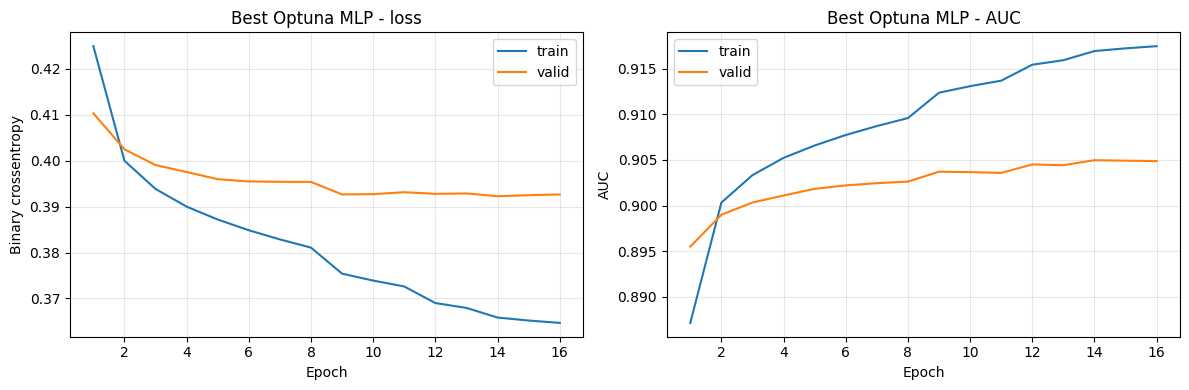

In [9]:
OPTUNA_EPOCHS = 16
OPTUNA_TRIALS = 12


def objective(trial: optuna.Trial) -> float:
    n_hidden = trial.suggest_int("n_hidden", 1, 4)
    n_units = trial.suggest_int("n_units", 32, 160, step=32)
    learning_rate = trial.suggest_float("learning_rate", 1e-4, 2e-3, log=True)
    batch_size = trial.suggest_categorical("batch_size", [256, 512, 1024])
    first_layer_wider = trial.suggest_categorical("first_layer_wider", [False, True])

    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)
    model = build_configurable_model(
        input_dim=INPUT_DIM,
        n_hidden=n_hidden,
        n_units=n_units,
        learning_rate=learning_rate,
        first_layer_wider=first_layer_wider,
    )

    history = model.fit(
        X_train_np,
        y_train_np,
        epochs=OPTUNA_EPOCHS,
        batch_size=batch_size,
        validation_data=(X_valid_np, y_valid_np),
        class_weight=class_weight,
        callbacks=make_callbacks(),
        verbose=0,
    )

    best_val_auc = max(history.history["val_auc"])
    trial.set_user_attr("epochs_trained", len(history.history["val_auc"]))
    return float(best_val_auc)


optuna_sampler = optuna.samplers.TPESampler(seed=SEED)
study = optuna.create_study(
    direction="maximize",
    sampler=optuna_sampler,
    study_name="higgs_mlp_optuna",
)

study.optimize(objective, n_trials=OPTUNA_TRIALS, show_progress_bar=False)

best_trial = study.best_trial
best_params = best_trial.params

print(f"Mejor trial: {best_trial.number}")
print(f"Mejor val_auc encontrado por Optuna: {best_trial.value:.4f}")
print("Mejores hiperparámetros encontrados:")
for name, value in best_params.items():
    print(f"- {name}: {value}")
print(f"Epochs entrenadas en el mejor trial: {best_trial.user_attrs['epochs_trained']}")


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
best_optuna_model = build_configurable_model(
    input_dim=INPUT_DIM,
    n_hidden=int(best_params["n_hidden"]),
    n_units=int(best_params["n_units"]),
    learning_rate=float(best_params["learning_rate"]),
    first_layer_wider=bool(best_params["first_layer_wider"]),
)

best_optuna_history = best_optuna_model.fit(
    X_train_np,
    y_train_np,
    epochs=OPTUNA_EPOCHS,
    batch_size=int(best_params["batch_size"]),
    validation_data=(X_valid_np, y_valid_np),
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

best_optuna_eval = final_metrics(best_optuna_model, "best_optuna")
optuna_trials_df = study.trials_dataframe(attrs=("number", "value", "params", "state", "user_attrs"))
optuna_trials_df = optuna_trials_df.sort_values("value", ascending=False).reset_index(drop=True)

optuna_summary_df = pd.DataFrame(
    [
        {
            **best_optuna_eval,
            **best_params,
            "epochs_ran": len(best_optuna_history.history["val_auc"]),
            "params": best_optuna_model.count_params(),
        }
    ]
)

print("Top trials de Optuna:")
display(optuna_trials_df.head().round(4))

print("Resumen del mejor modelo encontrado por Optuna:")
display(optuna_summary_df.round(4))
plot_history(best_optuna_history, "Best Optuna MLP")

## Parte 6 - Comparativa final

Esta sección junta los resultados de todas las etapas del notebook para poder responder una pregunta concreta: **qué enfoque mejora más al baseline en validación** y con qué tradeoff en `precision` y `recall`.

Comparativa final de modelos en validación:


,model,source,loss,accuracy,auc,precision,recall,delta_auc_vs_baseline,delta_recall_vs_baseline,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,epochs_ran,params
0,best_optuna,optuna,0.3923,0.8214,0.9050,0.7025,0.8304,0.0085,0.0035,2,160,0.0009,256,True,16,61601
1,best_keras_tuner,keras_tuner,0.4027,0.8142,0.9036,0.6862,0.8434,0.0071,0.0165,2,64,0.0019,1024,True,16,12353
2,same_hp_flipped_first_layer,manual_flip,0.3950,0.8200,0.9026,0.7025,0.8235,0.0061,-0.0034,2,64,0.0010,1024,False,12,6337
3,best_manual_search,manual_search,0.4028,0.8149,0.9019,0.6890,0.8380,0.0054,0.0111,2,64,0.0010,1024,True,12,12353
4,baseline,baseline,0.4078,0.8133,0.8965,0.6899,0.8269,0.0000,0.0000,1,32,0.0010,1024,False,20,897


Resultados completos de la búsqueda manual:


,name,n_hidden,n_units,learning_rate,first_layer_wider,accuracy,auc,loss,precision,recall,epochs_ran
0,cfg_2,2,64,0.0010,True,0.8149,0.9019,0.4028,0.6890,0.8380,12
1,cfg_3,2,128,0.0005,False,0.8154,0.9017,0.4018,0.6907,0.8355,12
2,cfg_4,3,96,0.0005,True,0.8190,0.9016,0.3982,0.6998,0.8263,12
3,cfg_5,3,128,0.0003,False,0.8170,0.9010,0.4018,0.6945,0.8320,12
4,cfg_1,1,64,0.0010,False,0.8083,0.8944,0.4141,0.6802,0.8317,12


Top trials de Optuna:


,number,value,params_batch_size,params_first_layer_wider,params_learning_rate,params_n_hidden,params_n_units,state,user_attrs_epochs_trained
0,0,0.9050,256,True,0.0009,2,160,COMPLETE,16
1,11,0.9046,256,True,0.0019,3,32,COMPLETE,16
2,6,0.9033,512,True,0.0018,3,32,COMPLETE,16
3,2,0.9024,512,True,0.0004,2,96,COMPLETE,16
4,10,0.9022,1024,True,0.0007,4,64,COMPLETE,16
5,1,0.9021,256,True,0.0001,3,128,COMPLETE,16
6,4,0.9020,256,False,0.0018,1,160,COMPLETE,16
7,3,0.9008,512,False,0.0002,2,128,COMPLETE,16
8,9,0.8988,512,False,0.0008,1,160,COMPLETE,16
9,8,0.8960,1024,False,0.0002,2,96,COMPLETE,16


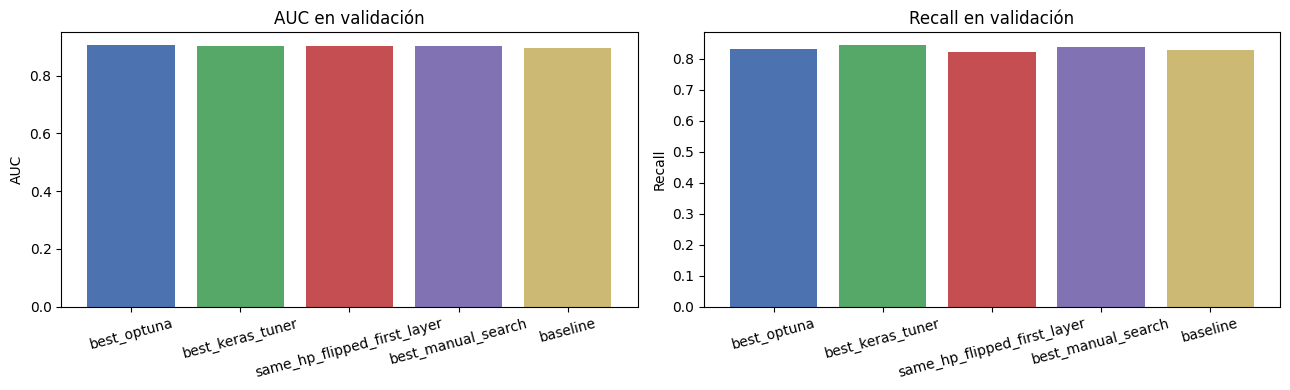

Mejor modelo por AUC: best_optuna (0.9050).
Delta AUC vs baseline: +0.0085.
Delta recall vs baseline: +0.0035.


In [10]:
required_objects = [
    "baseline_eval",
    "best_manual_eval",
    "flipped_eval",
    "best_tuner_eval",
    "best_optuna_eval",
    "search_results_df",
    "optuna_trials_df",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan variables para la comparativa final. Ejecutar primero las partes 2 a 5 completas: "
        + ", ".join(missing_objects)
    )

comparison_summary = pd.DataFrame([
    {
        "model": "baseline",
        **baseline_eval,
        "n_hidden": 1,
        "n_units": BASELINE_UNITS,
        "learning_rate": BASELINE_LR,
        "batch_size": BASELINE_BATCH_SIZE,
        "first_layer_wider": False,
        "epochs_ran": len(baseline_history.history["val_auc"]),
        "params": baseline_model.count_params(),
        "source": "baseline",
    },
    {
        **best_manual_eval,
        "n_hidden": int(best_manual_config["n_hidden"]),
        "n_units": int(best_manual_config["n_units"]),
        "learning_rate": float(best_manual_config["learning_rate"]),
        "batch_size": MANUAL_SEARCH_BATCH_SIZE,
        "first_layer_wider": bool(best_manual_config["first_layer_wider"]),
        "epochs_ran": len(best_manual_history.history["val_auc"]),
        "params": best_manual_model.count_params(),
        "source": "manual_search",
    },
    {
        **flipped_eval,
        "n_hidden": int(best_manual_config["n_hidden"]),
        "n_units": int(best_manual_config["n_units"]),
        "learning_rate": float(best_manual_config["learning_rate"]),
        "batch_size": MANUAL_SEARCH_BATCH_SIZE,
        "first_layer_wider": not bool(best_manual_config["first_layer_wider"]),
        "epochs_ran": len(flipped_first_layer_history.history["val_auc"]),
        "params": flipped_first_layer_model.count_params(),
        "source": "manual_flip",
    },
    {
        **best_tuner_eval,
        "n_hidden": int(best_hp.get("n_hidden")),
        "n_units": int(best_hp.get("n_units")),
        "learning_rate": float(best_hp.get("learning_rate")),
        "batch_size": TUNER_BATCH_SIZE,
        "first_layer_wider": bool(best_hp.get("first_layer_wider")),
        "epochs_ran": len(best_tuner_history.history["val_auc"]),
        "params": best_tuner_model.count_params(),
        "source": "keras_tuner",
    },
    {
        **best_optuna_eval,
        "n_hidden": int(best_params["n_hidden"]),
        "n_units": int(best_params["n_units"]),
        "learning_rate": float(best_params["learning_rate"]),
        "batch_size": int(best_params["batch_size"]),
        "first_layer_wider": bool(best_params["first_layer_wider"]),
        "epochs_ran": len(best_optuna_history.history["val_auc"]),
        "params": best_optuna_model.count_params(),
        "source": "optuna",
    },
]).sort_values(["auc", "recall"], ascending=False).reset_index(drop=True)

baseline_row = comparison_summary.loc[comparison_summary["model"] == "baseline"].iloc[0]
for metric in ["loss", "accuracy", "auc", "precision", "recall"]:
    comparison_summary[f"delta_{metric}_vs_baseline"] = (
        comparison_summary[metric] - float(baseline_row[metric])
    )

summary_columns = [
    "model",
    "source",
    "loss",
    "accuracy",
    "auc",
    "precision",
    "recall",
    "delta_auc_vs_baseline",
    "delta_recall_vs_baseline",
    "n_hidden",
    "n_units",
    "learning_rate",
    "batch_size",
    "first_layer_wider",
    "epochs_ran",
    "params",
]

print("Comparativa final de modelos en validación:")
display(comparison_summary[summary_columns].round(4))

print("Resultados completos de la búsqueda manual:")
display(search_results_df.round(4))

print("Top trials de Optuna:")
display(optuna_trials_df.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
bar_colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3", "#CCB974"][: len(comparison_summary)]

axes[0].bar(comparison_summary["model"], comparison_summary["auc"], color=bar_colors)
axes[0].set_title("AUC en validación")
axes[0].set_ylabel("AUC")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(comparison_summary["model"], comparison_summary["recall"], color=bar_colors)
axes[1].set_title("Recall en validación")
axes[1].set_ylabel("Recall")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

best_row = comparison_summary.iloc[0]
print(f"Mejor modelo por AUC: {best_row['model']} ({best_row['auc']:.4f}).")
print(f"Delta AUC vs baseline: {best_row['delta_auc_vs_baseline']:+.4f}.")
print(f"Delta recall vs baseline: {best_row['delta_recall_vs_baseline']:+.4f}.")

## Cierre

La salida de este notebook deja cuatro niveles de referencia para seguir trabajando:

- el `baseline` simple,
- una búsqueda manual corta,
- una búsqueda con `Keras Tuner`,
- y una búsqueda con `Optuna`.

El objetivo en esta etapa no es cerrar todavía un modelo final de submission, sino entender mejor qué hiperparámetros parecen mover realmente el rendimiento en validación. Si una de estas variantes muestra mejoras consistentes sobre el baseline, el siguiente paso razonable sería profundizar sobre esa familia de modelos y recién después pensar la inferencia sobre `X_test_processed`.

## Parte 7 - Reentrenamiento del mejor modelo con weight decay

Si el mejor modelo de la comparativa final está sobreajustando, una forma simple de atacarlo sin cambiar la familia del modelo es volver a entrenarlo con los mismos hiperparámetros, agregando regularización `L2` en las capas densas.

La idea de esta sección es comparar:

- el mejor modelo original,
- la misma arquitectura con `weight_decay`,
- sus métricas finales en validación,
- y la traza `train/valid` para ver si baja el gap de generalización.


Mejor modelo elegido para reentrenar:


,model,accuracy,auc,loss,precision,recall,n_hidden,n_units,learning_rate,batch_size,first_layer_wider,epochs_ran,params,source,delta_loss_vs_baseline,delta_accuracy_vs_baseline,delta_auc_vs_baseline,delta_precision_vs_baseline,delta_recall_vs_baseline
0,best_optuna,0.8214,0.904972,0.392262,0.702548,0.830396,2,160,0.000896,256,True,16,61601,optuna,-0.015544,0.00808,0.00847,0.012637,0.003502


Weight decay a probar: 0.0001


W0000 00:00:1776608144.458845   17784 cpu_allocator_impl.cc:82] Allocation of 23400000 exceeds 10% of free system memory.


Comparación del mejor modelo original vs la versión con weight decay:


,run,weight_decay,epochs_ran,loss,auc,precision,recall,best_epoch_val_auc,best_val_auc,gap_auc_at_best_val_auc,best_epoch_val_loss,best_val_loss,gap_loss_at_best_val_loss,delta_auc_vs_original,delta_recall_vs_original,delta_best_val_auc_vs_original,delta_gap_auc_at_best_val_auc_vs_original,delta_gap_loss_at_best_val_loss_vs_original
0,original,0.0000,16,0.3923,0.9050,0.7025,0.8304,14,0.9050,0.0120,14,0.3923,0.0264,0.0000,0.0000,0.0000,0.0000,0.0000
1,with_weight_decay,0.0001,16,0.4104,0.9037,0.6974,0.8292,15,0.9037,0.0055,16,0.4101,0.0158,-0.0013,-0.0012,-0.0013,-0.0065,-0.0107


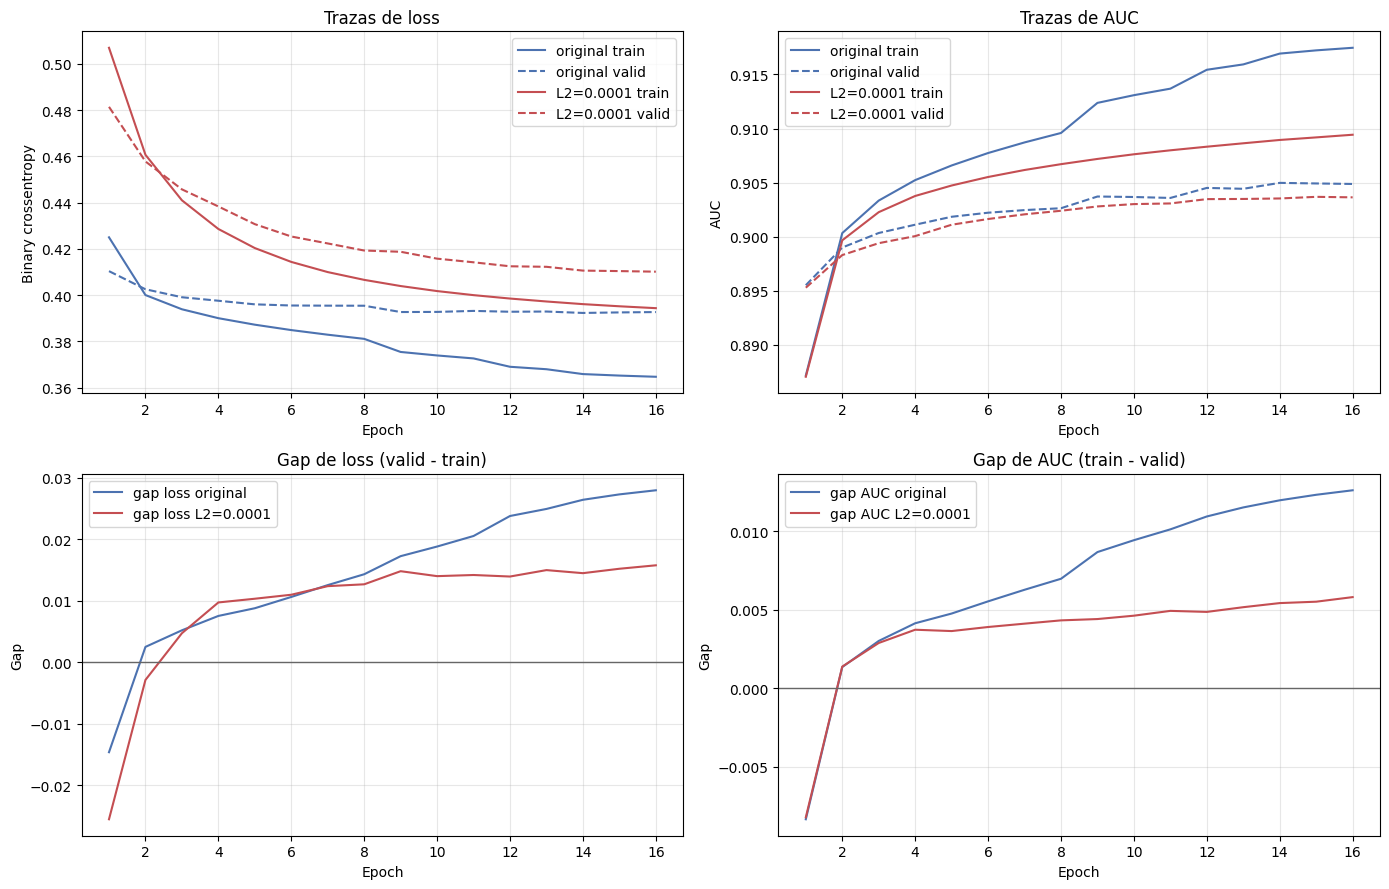

In [13]:
WEIGHT_DECAY = 1e-4

required_objects = [
    "comparison_summary",
    "best_row",
    "baseline_model",
    "baseline_history",
    "best_manual_model",
    "best_manual_history",
    "flipped_first_layer_model",
    "flipped_first_layer_history",
    "best_tuner_model",
    "best_tuner_history",
    "best_optuna_model",
    "best_optuna_history",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan variables para la comparación con weight decay. Ejecutar primero las partes 2 a 6 completas: "
        + ", ".join(missing_objects)
    )


def build_model_from_row_with_weight_decay(row: pd.Series, weight_decay: float) -> keras.Model:
    regularizer = keras.regularizers.l2(weight_decay) if weight_decay > 0 else None
    learning_rate = float(row["learning_rate"])

    if str(row["model"]) == "baseline":
        model = keras.Sequential([
            keras.layers.Input(shape=(INPUT_DIM,)),
            keras.layers.Dense(
                int(row["n_units"]),
                activation="relu",
                kernel_initializer="he_normal",
                kernel_regularizer=regularizer,
            ),
            keras.layers.Dense(
                1,
                activation="sigmoid",
                kernel_regularizer=regularizer,
            ),
        ])
    else:
        inputs = keras.layers.Input(shape=(INPUT_DIM,))
        x = inputs

        for layer_idx in range(int(row["n_hidden"])):
            units = int(row["n_units"]) * 2 if bool(row["first_layer_wider"]) and layer_idx == 0 else int(row["n_units"])
            x = keras.layers.Dense(
                units,
                kernel_initializer="he_normal",
                use_bias=False,
                kernel_regularizer=regularizer,
            )(x)
            x = keras.layers.BatchNormalization()(x)
            x = keras.layers.Activation("relu")(x)

        outputs = keras.layers.Dense(
            1,
            activation="sigmoid",
            kernel_regularizer=regularizer,
        )(x)
        model = keras.Model(inputs, outputs)

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc"),
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
        ],
    )
    return model


def summarize_history(label: str, history: keras.callbacks.History, metrics: dict, weight_decay: float) -> dict:
    history_df = pd.DataFrame(history.history)
    best_val_auc_idx = int(history_df["val_auc"].idxmax())
    best_val_loss_idx = int(history_df["val_loss"].idxmin())

    return {
        "run": label,
        "weight_decay": weight_decay,
        "epochs_ran": len(history_df),
        "best_epoch_val_auc": best_val_auc_idx + 1,
        "best_val_auc": float(history_df.loc[best_val_auc_idx, "val_auc"]),
        "gap_auc_at_best_val_auc": float(
            history_df.loc[best_val_auc_idx, "auc"] - history_df.loc[best_val_auc_idx, "val_auc"]
        ),
        "best_epoch_val_loss": best_val_loss_idx + 1,
        "best_val_loss": float(history_df.loc[best_val_loss_idx, "val_loss"]),
        "gap_loss_at_best_val_loss": float(
            history_df.loc[best_val_loss_idx, "val_loss"] - history_df.loc[best_val_loss_idx, "loss"]
        ),
        **{metric: float(value) for metric, value in metrics.items() if metric != "model"},
    }


def plot_weight_decay_comparison(
    original_history: keras.callbacks.History,
    regularized_history: keras.callbacks.History,
    original_label: str,
    regularized_label: str,
) -> None:
    original_df = pd.DataFrame(original_history.history)
    regularized_df = pd.DataFrame(regularized_history.history)
    original_epochs = original_df.index + 1
    regularized_epochs = regularized_df.index + 1

    fig, axes = plt.subplots(2, 2, figsize=(14, 9))

    axes[0, 0].plot(original_epochs, original_df["loss"], color="#4C72B0", label=f"{original_label} train")
    axes[0, 0].plot(original_epochs, original_df["val_loss"], color="#4C72B0", linestyle="--", label=f"{original_label} valid")
    axes[0, 0].plot(regularized_epochs, regularized_df["loss"], color="#C44E52", label=f"{regularized_label} train")
    axes[0, 0].plot(regularized_epochs, regularized_df["val_loss"], color="#C44E52", linestyle="--", label=f"{regularized_label} valid")
    axes[0, 0].set_title("Trazas de loss")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Binary crossentropy")
    axes[0, 0].grid(alpha=0.3)
    axes[0, 0].legend()

    axes[0, 1].plot(original_epochs, original_df["auc"], color="#4C72B0", label=f"{original_label} train")
    axes[0, 1].plot(original_epochs, original_df["val_auc"], color="#4C72B0", linestyle="--", label=f"{original_label} valid")
    axes[0, 1].plot(regularized_epochs, regularized_df["auc"], color="#C44E52", label=f"{regularized_label} train")
    axes[0, 1].plot(regularized_epochs, regularized_df["val_auc"], color="#C44E52", linestyle="--", label=f"{regularized_label} valid")
    axes[0, 1].set_title("Trazas de AUC")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("AUC")
    axes[0, 1].grid(alpha=0.3)
    axes[0, 1].legend()

    axes[1, 0].plot(
        original_epochs,
        original_df["val_loss"] - original_df["loss"],
        color="#4C72B0",
        label=f"gap loss {original_label}",
    )
    axes[1, 0].plot(
        regularized_epochs,
        regularized_df["val_loss"] - regularized_df["loss"],
        color="#C44E52",
        label=f"gap loss {regularized_label}",
    )
    axes[1, 0].axhline(0.0, color="#666666", linewidth=1.0)
    axes[1, 0].set_title("Gap de loss (valid - train)")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylabel("Gap")
    axes[1, 0].grid(alpha=0.3)
    axes[1, 0].legend()

    axes[1, 1].plot(
        original_epochs,
        original_df["auc"] - original_df["val_auc"],
        color="#4C72B0",
        label=f"gap AUC {original_label}",
    )
    axes[1, 1].plot(
        regularized_epochs,
        regularized_df["auc"] - regularized_df["val_auc"],
        color="#C44E52",
        label=f"gap AUC {regularized_label}",
    )
    axes[1, 1].axhline(0.0, color="#666666", linewidth=1.0)
    axes[1, 1].set_title("Gap de AUC (train - valid)")
    axes[1, 1].set_xlabel("Epoch")
    axes[1, 1].set_ylabel("Gap")
    axes[1, 1].grid(alpha=0.3)
    axes[1, 1].legend()

    plt.tight_layout()
    plt.show()


best_model_registry = {
    "baseline": {
        "model": baseline_model,
        "history": baseline_history,
        "max_epochs": BASELINE_EPOCHS,
        "batch_size": BASELINE_BATCH_SIZE,
    },
    "best_manual_search": {
        "model": best_manual_model,
        "history": best_manual_history,
        "max_epochs": MANUAL_SEARCH_EPOCHS,
        "batch_size": MANUAL_SEARCH_BATCH_SIZE,
    },
    "same_hp_flipped_first_layer": {
        "model": flipped_first_layer_model,
        "history": flipped_first_layer_history,
        "max_epochs": MANUAL_SEARCH_EPOCHS,
        "batch_size": MANUAL_SEARCH_BATCH_SIZE,
    },
    "best_keras_tuner": {
        "model": best_tuner_model,
        "history": best_tuner_history,
        "max_epochs": TUNER_EPOCHS,
        "batch_size": TUNER_BATCH_SIZE,
    },
    "best_optuna": {
        "model": best_optuna_model,
        "history": best_optuna_history,
        "max_epochs": OPTUNA_EPOCHS,
        "batch_size": int(best_params["batch_size"]),
    },
}

selected_model_name = str(best_row["model"])
selected_model_bundle = best_model_registry[selected_model_name]
selected_original_model = selected_model_bundle["model"]
selected_original_history = selected_model_bundle["history"]
selected_batch_size = int(selected_model_bundle["batch_size"])
selected_max_epochs = int(selected_model_bundle["max_epochs"])

selected_original_eval = final_metrics(selected_original_model, f"{selected_model_name}_original")

print("Mejor modelo elegido para reentrenar:")
display(best_row.to_frame().T.round(4))
print(f"Weight decay a probar: {WEIGHT_DECAY}")


tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
best_weight_decay_model = build_model_from_row_with_weight_decay(best_row, weight_decay=WEIGHT_DECAY)
best_weight_decay_history = best_weight_decay_model.fit(
    X_train_np,
    y_train_np,
    validation_data=(X_valid_np, y_valid_np),
    epochs=selected_max_epochs,
    batch_size=selected_batch_size,
    class_weight=class_weight,
    callbacks=make_callbacks(),
    verbose=0,
)

best_weight_decay_eval = final_metrics(best_weight_decay_model, f"{selected_model_name}_with_weight_decay")

weight_decay_comparison_df = pd.DataFrame([
    summarize_history(
        label="original",
        history=selected_original_history,
        metrics=selected_original_eval,
        weight_decay=0.0,
    ),
    summarize_history(
        label="with_weight_decay",
        history=best_weight_decay_history,
        metrics=best_weight_decay_eval,
        weight_decay=WEIGHT_DECAY,
    ),
])

reference_row = weight_decay_comparison_df.loc[weight_decay_comparison_df["run"] == "original"].iloc[0]
for metric in [
    "loss",
    "accuracy",
    "auc",
    "precision",
    "recall",
    "best_val_auc",
    "best_val_loss",
    "gap_auc_at_best_val_auc",
    "gap_loss_at_best_val_loss",
]:
    weight_decay_comparison_df[f"delta_{metric}_vs_original"] = (
        weight_decay_comparison_df[metric] - float(reference_row[metric])
    )

comparison_columns = [
    "run",
    "weight_decay",
    "epochs_ran",
    "loss",
    "auc",
    "precision",
    "recall",
    "best_epoch_val_auc",
    "best_val_auc",
    "gap_auc_at_best_val_auc",
    "best_epoch_val_loss",
    "best_val_loss",
    "gap_loss_at_best_val_loss",
    "delta_auc_vs_original",
    "delta_recall_vs_original",
    "delta_best_val_auc_vs_original",
    "delta_gap_auc_at_best_val_auc_vs_original",
    "delta_gap_loss_at_best_val_loss_vs_original",
]

print("Comparación del mejor modelo original vs la versión con weight decay:")
display(weight_decay_comparison_df[comparison_columns].round(4))

plot_weight_decay_comparison(
    original_history=selected_original_history,
    regularized_history=best_weight_decay_history,
    original_label="original",
    regularized_label=f"L2={WEIGHT_DECAY}",
)


## Parte 8 - Búsqueda del mejor weight decay

Después de probar un valor puntual, esta sección hace una búsqueda corta sobre una grilla logarítmica de `weight_decay`, manteniendo fija la arquitectura del mejor modelo y su configuración de entrenamiento.

La grilla incluye `0.0` como control, para poder ver si la regularización mejora realmente la generalización o si el modelo original sigue siendo la mejor opción.


Resultados de la búsqueda de weight decay:


,weight_decay_label,weight_decay,epochs_ran,auc,precision,recall,best_epoch_val_auc,best_val_auc,gap_auc_at_best_val_auc,best_epoch_val_loss,best_val_loss,gap_loss_at_best_val_loss,delta_best_val_auc_vs_no_weight_decay,delta_gap_auc_at_best_val_auc_vs_no_weight_decay
0,0,0.0000,16,0.9050,0.7025,0.8304,14,0.9050,0.0120,14,0.3923,0.0264,0.0000,0.0000
1,3e-04,0.0003,16,0.9046,0.6967,0.8332,16,0.9046,0.0051,15,0.4065,0.0139,-0.0004,-0.0069
2,1e-06,0.0000,16,0.9045,0.7031,0.8284,15,0.9045,0.0130,12,0.3940,0.0218,-0.0004,0.0011
3,3e-05,0.0000,16,0.9042,0.7011,0.8272,14,0.9042,0.0097,16,0.4061,0.0237,-0.0008,-0.0022
4,1e-03,0.0010,16,0.9041,0.6942,0.8367,16,0.9041,0.0029,15,0.4092,0.0110,-0.0008,-0.0090
5,1e-05,0.0000,14,0.9039,0.7042,0.8239,10,0.9039,0.0088,13,0.4000,0.0205,-0.0011,-0.0032
6,1e-04,0.0001,16,0.9037,0.6974,0.8292,15,0.9037,0.0055,16,0.4101,0.0158,-0.0013,-0.0065


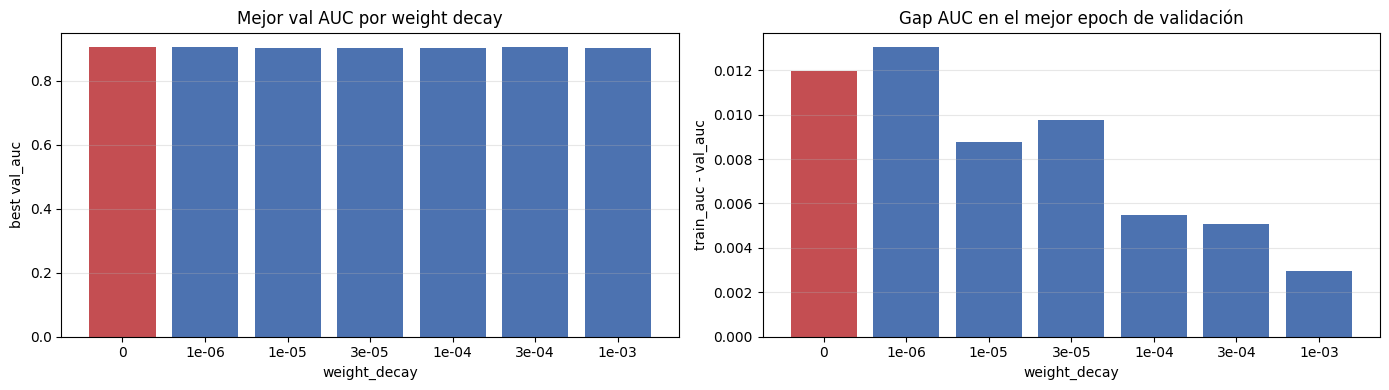

Mejor weight decay de la grilla: 0 (best_val_auc=0.9050).
En esta grilla, el control sin regularización sigue siendo el mejor. Abajo se compara igual contra la mejor variante regularizada para inspeccionar el tradeoff.


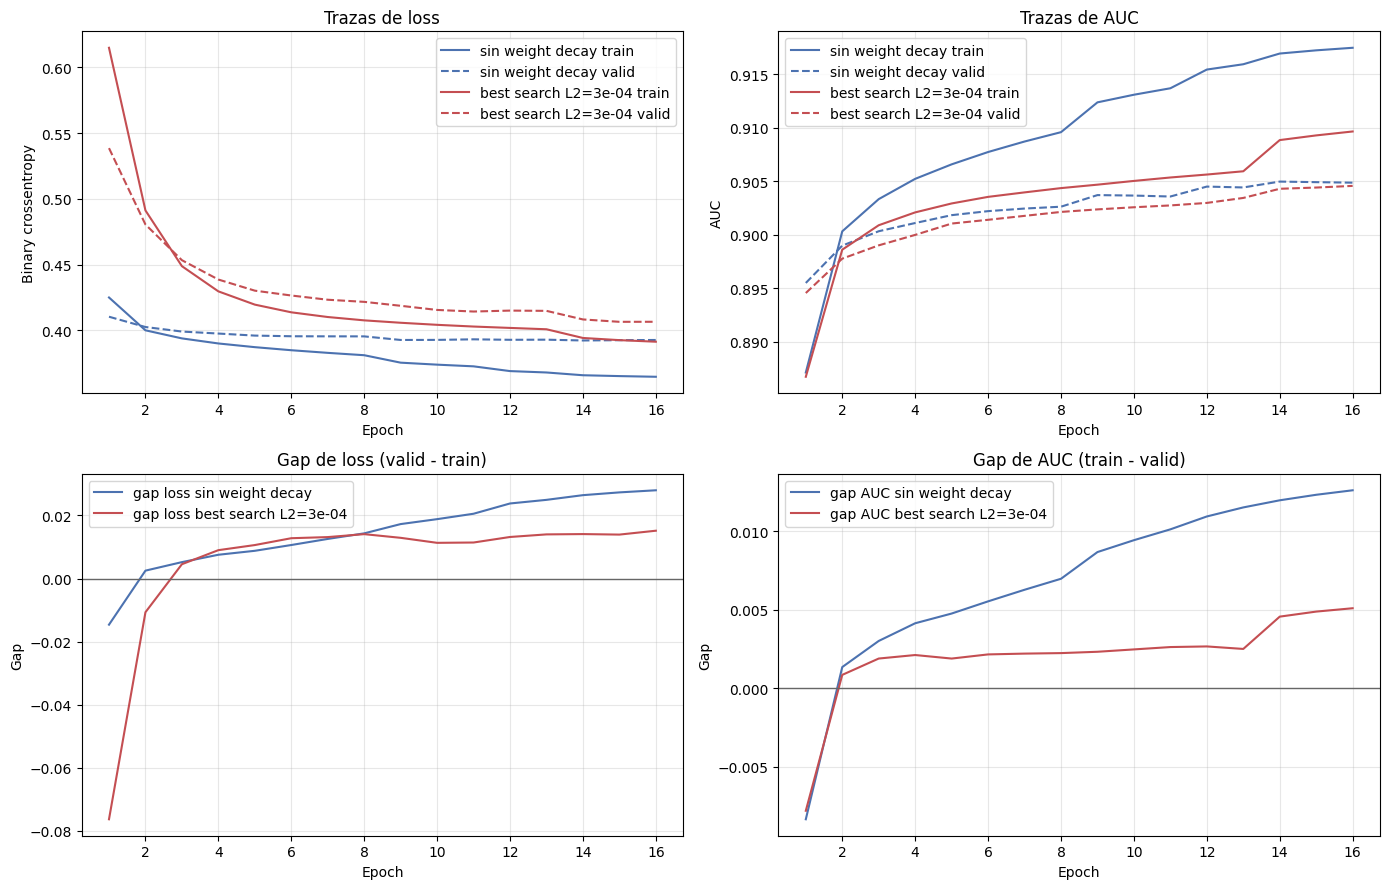

In [14]:
WEIGHT_DECAY_GRID = [1e-6, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3]

required_objects = [
    "best_row",
    "selected_model_name",
    "selected_original_history",
    "selected_original_eval",
    "selected_batch_size",
    "selected_max_epochs",
    "build_model_from_row_with_weight_decay",
    "summarize_history",
    "plot_weight_decay_comparison",
    "class_weight",
    "X_train_np",
    "y_train_np",
    "X_valid_np",
    "y_valid_np",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan variables para la búsqueda de weight decay. Ejecutar primero la Parte 7 completa: "
        + ", ".join(missing_objects)
    )


def format_weight_decay(value: float) -> str:
    return "0" if float(value) == 0.0 else f"{float(value):.0e}"


weight_decay_search_rows = [
    summarize_history(
        label="wd_0",
        history=selected_original_history,
        metrics=selected_original_eval,
        weight_decay=0.0,
    )
]
weight_decay_search_histories = {0.0: selected_original_history}

for weight_decay in WEIGHT_DECAY_GRID:
    if (
        np.isclose(weight_decay, WEIGHT_DECAY)
        and "best_weight_decay_history" in globals()
        and "best_weight_decay_eval" in globals()
    ):
        history = best_weight_decay_history
        eval_metrics = best_weight_decay_eval
    else:
        tf.keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        model = build_model_from_row_with_weight_decay(best_row, weight_decay=weight_decay)
        history = model.fit(
            X_train_np,
            y_train_np,
            validation_data=(X_valid_np, y_valid_np),
            epochs=selected_max_epochs,
            batch_size=selected_batch_size,
            class_weight=class_weight,
            callbacks=make_callbacks(),
            verbose=0,
        )
        eval_metrics = final_metrics(
            model,
            f"{selected_model_name}_wd_{format_weight_decay(weight_decay)}",
        )

    weight_decay_search_histories[float(weight_decay)] = history
    weight_decay_search_rows.append(
        summarize_history(
            label=f"wd_{format_weight_decay(weight_decay)}",
            history=history,
            metrics=eval_metrics,
            weight_decay=float(weight_decay),
        )
    )

weight_decay_search_df = pd.DataFrame(weight_decay_search_rows)
weight_decay_search_df["weight_decay_label"] = weight_decay_search_df["weight_decay"].map(format_weight_decay)

reference_row = weight_decay_search_df.loc[weight_decay_search_df["weight_decay"] == 0.0].iloc[0]
for metric in [
    "loss",
    "accuracy",
    "auc",
    "precision",
    "recall",
    "best_val_auc",
    "best_val_loss",
    "gap_auc_at_best_val_auc",
    "gap_loss_at_best_val_loss",
]:
    weight_decay_search_df[f"delta_{metric}_vs_no_weight_decay"] = (
        weight_decay_search_df[metric] - float(reference_row[metric])
    )

weight_decay_search_df = weight_decay_search_df.sort_values(
    ["best_val_auc", "gap_auc_at_best_val_auc", "best_val_loss"],
    ascending=[False, True, True],
).reset_index(drop=True)

search_columns = [
    "weight_decay_label",
    "weight_decay",
    "epochs_ran",
    "auc",
    "precision",
    "recall",
    "best_epoch_val_auc",
    "best_val_auc",
    "gap_auc_at_best_val_auc",
    "best_epoch_val_loss",
    "best_val_loss",
    "gap_loss_at_best_val_loss",
    "delta_best_val_auc_vs_no_weight_decay",
    "delta_gap_auc_at_best_val_auc_vs_no_weight_decay",
]

print("Resultados de la búsqueda de weight decay:")
display(weight_decay_search_df[search_columns].round(4))

searched_best_row = weight_decay_search_df.iloc[0]
positive_weight_decay_df = weight_decay_search_df.loc[weight_decay_search_df["weight_decay"] > 0].reset_index(drop=True)
best_regularized_row = positive_weight_decay_df.iloc[0]

plot_df = weight_decay_search_df.sort_values("weight_decay").copy()
bar_colors = [
    "#C44E52" if np.isclose(value, float(searched_best_row["weight_decay"])) else "#4C72B0"
    for value in plot_df["weight_decay"]
]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(plot_df["weight_decay_label"], plot_df["best_val_auc"], color=bar_colors)
axes[0].set_title("Mejor val AUC por weight decay")
axes[0].set_xlabel("weight_decay")
axes[0].set_ylabel("best val_auc")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(plot_df["weight_decay_label"], plot_df["gap_auc_at_best_val_auc"], color=bar_colors)
axes[1].set_title("Gap AUC en el mejor epoch de validación")
axes[1].set_xlabel("weight_decay")
axes[1].set_ylabel("train_auc - val_auc")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(
    "Mejor weight decay de la grilla: "
    f"{format_weight_decay(float(searched_best_row['weight_decay']))} "
    f"(best_val_auc={float(searched_best_row['best_val_auc']):.4f})."
)

trace_comparison_row = best_regularized_row
if np.isclose(float(searched_best_row["weight_decay"]), 0.0):
    print(
        "En esta grilla, el control sin regularización sigue siendo el mejor. "
        "Abajo se compara igual contra la mejor variante regularizada para inspeccionar el tradeoff."
    )
else:
    trace_comparison_row = searched_best_row

trace_weight_decay = float(trace_comparison_row["weight_decay"])
trace_history = weight_decay_search_histories[trace_weight_decay]

plot_weight_decay_comparison(
    original_history=selected_original_history,
    regularized_history=trace_history,
    original_label="sin weight decay",
    regularized_label=f"best search L2={format_weight_decay(trace_weight_decay)}",
)
